# 🔍 Fraud Detection in Mobile Financial Transactions
### Machine Learning Pipeline — Logistic Regression · Decision Tree · Random Forest · AdaBoost · XGBoost

**Goal:** Build and evaluate multiple classifiers to detect fraudulent transactions with high precision and recall.


## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)


## Step 2: Load Dataset

In [3]:
# Load the fraud dataset
df = pd.read_csv('Fraud_Analysis_Dataset(in).csv')

print(f"Dataset Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
df.head()


Dataset Shape: (11142, 10)

Columns: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud']


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,1,TRANSFER,181.0,C1305486145,181.0,0.0,C553264065,0.0,0.0,1
1,1,CASH_OUT,181.0,C840083671,181.0,0.0,C38997010,21182.0,0.0,1
2,1,TRANSFER,2806.0,C1420196421,2806.0,0.0,C972765878,0.0,0.0,1
3,1,CASH_OUT,2806.0,C2101527076,2806.0,0.0,C1007251739,26202.0,0.0,1
4,1,TRANSFER,20128.0,C137533655,20128.0,0.0,C1848415041,0.0,0.0,1


## Step 3: Exploratory Data Analysis (EDA)
Understanding transaction patterns and fraud indicators.

In [4]:
# Basic info
print("Data Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())


Data Types:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
dtype: object

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
dtype: int64


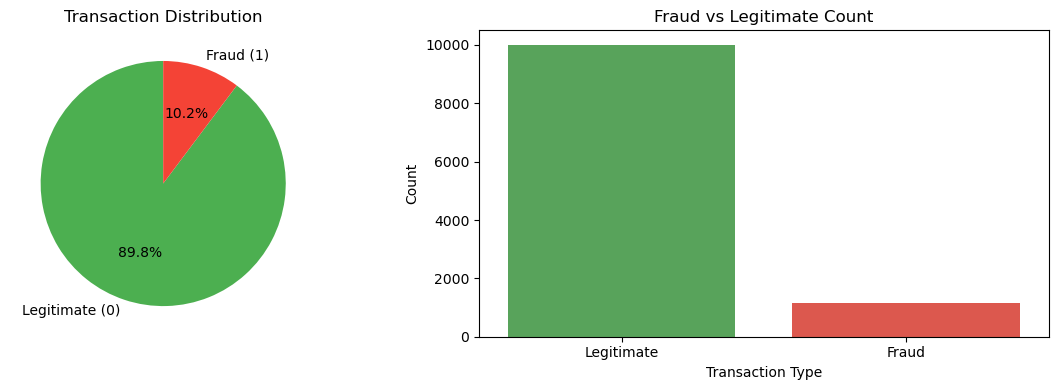

Legitimate Transactions: 10,000
Fraudulent Transactions: 1,142
Fraud Rate: 10.25%


In [5]:
# Target distribution
fraud_counts = df['isFraud'].value_counts()
labels = ['Legitimate (0)', 'Fraud (1)']

plt.figure(figsize=(12, 4))

# Pie chart
plt.subplot(1, 2, 1)
plt.pie(fraud_counts, labels=labels, autopct='%1.1f%%', colors=['#4CAF50', '#F44336'], startangle=90)
plt.title('Transaction Distribution')

# Bar chart
plt.subplot(1, 2, 2)
sns.countplot(x='isFraud', data=df, palette=['#4CAF50', '#F44336'])
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.title('Fraud vs Legitimate Count')
plt.xlabel('Transaction Type')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

print(f"Legitimate Transactions: {fraud_counts[0]:,}")
print(f"Fraudulent Transactions: {fraud_counts[1]:,}")
print(f"Fraud Rate: {fraud_counts[1]/len(df)*100:.2f}%")


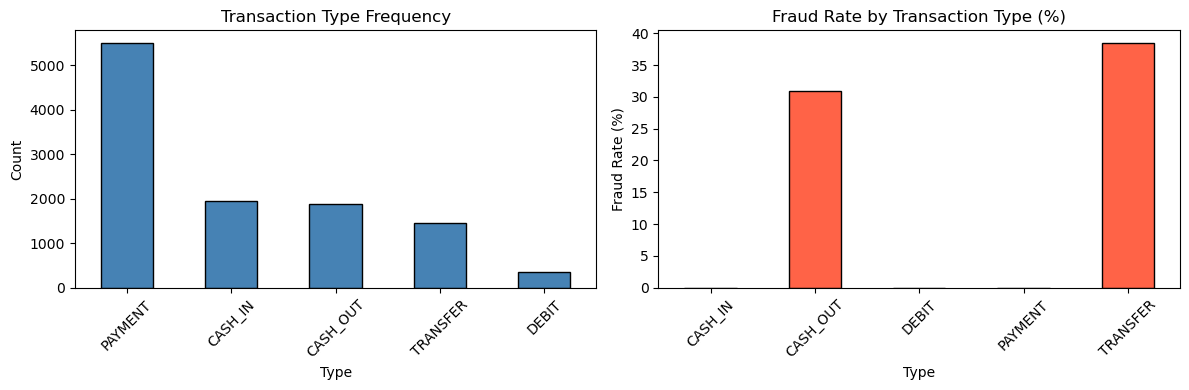

In [6]:
# Transaction type distribution
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
df['type'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Transaction Type Frequency')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Fraud by transaction type
plt.subplot(1, 2, 2)
fraud_by_type = df.groupby('type')['isFraud'].mean() * 100
fraud_by_type.plot(kind='bar', color='tomato', edgecolor='black')
plt.title('Fraud Rate by Transaction Type (%)')
plt.xlabel('Type')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


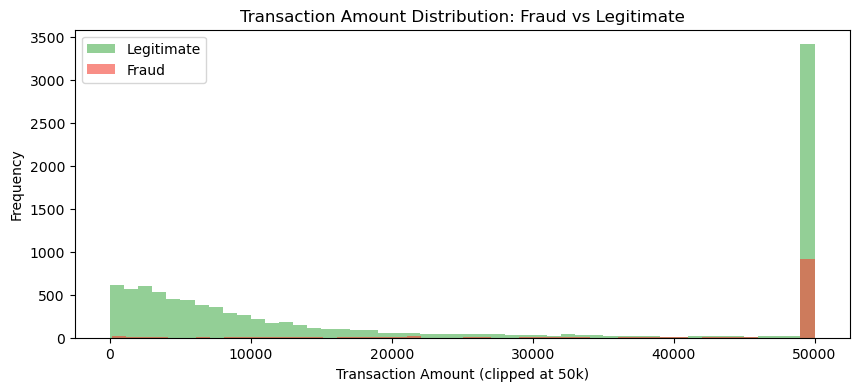

In [7]:
# Amount distribution for fraud vs legitimate
plt.figure(figsize=(10, 4))
df[df['isFraud'] == 0]['amount'].clip(upper=50000).plot(kind='hist', bins=50, alpha=0.6, color='#4CAF50', label='Legitimate')
df[df['isFraud'] == 1]['amount'].clip(upper=50000).plot(kind='hist', bins=50, alpha=0.6, color='#F44336', label='Fraud')
plt.xlabel('Transaction Amount (clipped at 50k)')
plt.ylabel('Frequency')
plt.title('Transaction Amount Distribution: Fraud vs Legitimate')
plt.legend()
plt.show()


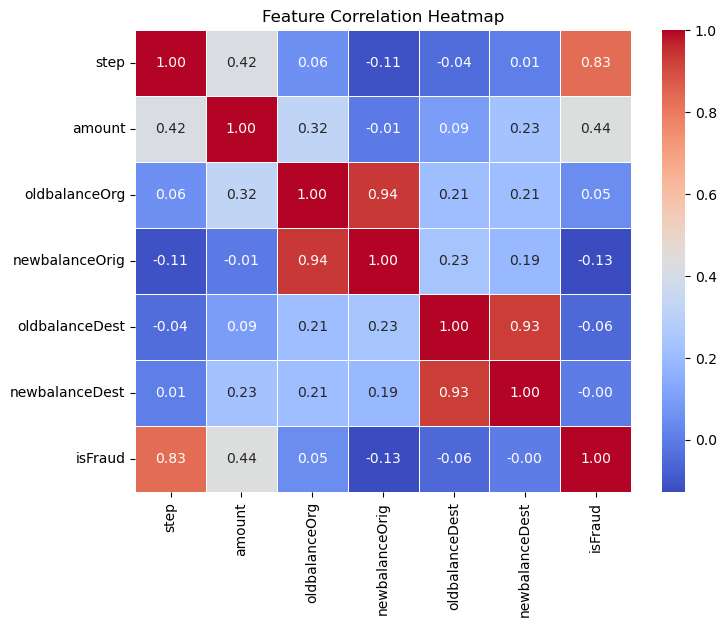

In [8]:
# Correlation heatmap
plt.figure(figsize=(8, 6))
numeric_cols = ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFraud']
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()


## Step 4: Feature Engineering
Creating new features and applying One-Hot Encoding for the categorical `type` column.



In [9]:

type_dummies = pd.get_dummies(df['type'], prefix='type', drop_first=True)

print("One-Hot Encoded Columns:")
print(list(type_dummies.columns))
type_dummies.head()


One-Hot Encoded Columns:
['type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,False,False,False,True
1,True,False,False,False
2,False,False,False,True
3,True,False,False,False
4,False,False,False,True


In [11]:
# Create new meaningful features
df['balance_diff_orig'] = df['oldbalanceOrg'] - df['newbalanceOrig']   # How much sender lost
df['balance_diff_dest'] = df['newbalanceDest'] - df['oldbalanceDest']  # How much receiver gained

# Combine original numeric features + one-hot encoded type columns
numeric_features = [
    'step',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'balance_diff_orig',
    'balance_diff_dest'
]

X = pd.concat([df[numeric_features], type_dummies], axis=1)
y = df['isFraud']

# Store final feature names for importance plots later
features = list(X.columns)




## Step 5: Train / Test Split

In [12]:
# Split data: 80% training, 20% testing
# stratify=y ensures both splits have the same fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)




## Step 6: Model 1 — Logistic Regression

In [13]:
# Logistic Regression — Linear baseline model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# Predictions
lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluation
print("=== Logistic Regression ===")
print(f"ROC-AUC Score: {roc_auc_score(y_test, lr_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, lr_pred, target_names=['Legitimate', 'Fraud']))


=== Logistic Regression ===
ROC-AUC Score: 0.9912

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99      2001
       Fraud       1.00      0.90      0.95       228

    accuracy                           0.99      2229
   macro avg       0.99      0.95      0.97      2229
weighted avg       0.99      0.99      0.99      2229



## Step 7: Model 2 — Decision Tree

In [14]:
# Decision Tree — Rule-based interpretable model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("=== Decision Tree ===")
print(f"ROC-AUC Score: {roc_auc_score(y_test, dt_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, dt_pred, target_names=['Legitimate', 'Fraud']))


=== Decision Tree ===
ROC-AUC Score: 0.9812

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      2001
       Fraud       0.98      0.96      0.97       228

    accuracy                           0.99      2229
   macro avg       0.99      0.98      0.98      2229
weighted avg       0.99      0.99      0.99      2229



## Step 8: Model 3 — Random Forest

In [15]:
# Random Forest — Ensemble of decision trees (reduces overfitting)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("=== Random Forest ===")
print(f"ROC-AUC Score: {roc_auc_score(y_test, rf_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, rf_pred, target_names=['Legitimate', 'Fraud']))


=== Random Forest ===
ROC-AUC Score: 0.9999

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      2001
       Fraud       1.00      0.96      0.98       228

    accuracy                           1.00      2229
   macro avg       1.00      0.98      0.99      2229
weighted avg       1.00      1.00      1.00      2229



## Step 9: Model 4 — AdaBoost

In [16]:
# AdaBoost — Boosting: focuses on samples misclassified by previous trees
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train, y_train)

ada_pred = ada_model.predict(X_test)
ada_prob = ada_model.predict_proba(X_test)[:, 1]

print("=== AdaBoost ===")
print(f"ROC-AUC Score: {roc_auc_score(y_test, ada_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, ada_pred, target_names=['Legitimate', 'Fraud']))


=== AdaBoost ===
ROC-AUC Score: 0.9994

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      2001
       Fraud       1.00      0.97      0.99       228

    accuracy                           1.00      2229
   macro avg       1.00      0.99      0.99      2229
weighted avg       1.00      1.00      1.00      2229



## Step 10: Model 5 — XGBoost

In [17]:
# XGBoost — Gradient boosting with regularization; top performer in tabular tasks
xgb_model = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("=== XGBoost ===")
print(f"ROC-AUC Score: {roc_auc_score(y_test, xgb_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, xgb_pred, target_names=['Legitimate', 'Fraud']))


=== XGBoost ===
ROC-AUC Score: 1.0000

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      2001
       Fraud       1.00      0.98      0.99       228

    accuracy                           1.00      2229
   macro avg       1.00      0.99      1.00      2229
weighted avg       1.00      1.00      1.00      2229



## Step 11: Confusion Matrices — All Models

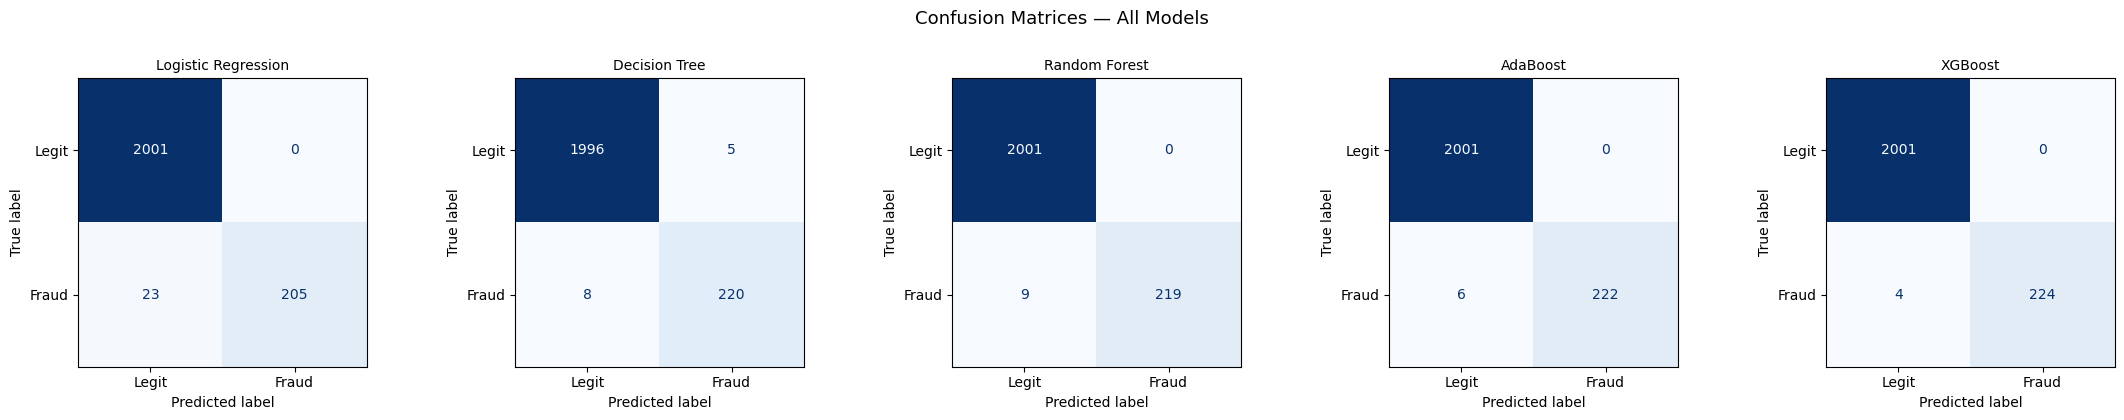

In [18]:
# Plot confusion matrices for all 5 models side by side
model_names  = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'AdaBoost', 'XGBoost']
all_preds    = [lr_pred, dt_pred, rf_pred, ada_pred, xgb_pred]

fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, name, pred in zip(axes, model_names, all_preds):
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legit', 'Fraud'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)

plt.suptitle('Confusion Matrices — All Models', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


## Step 12: ROC Curves Comparison

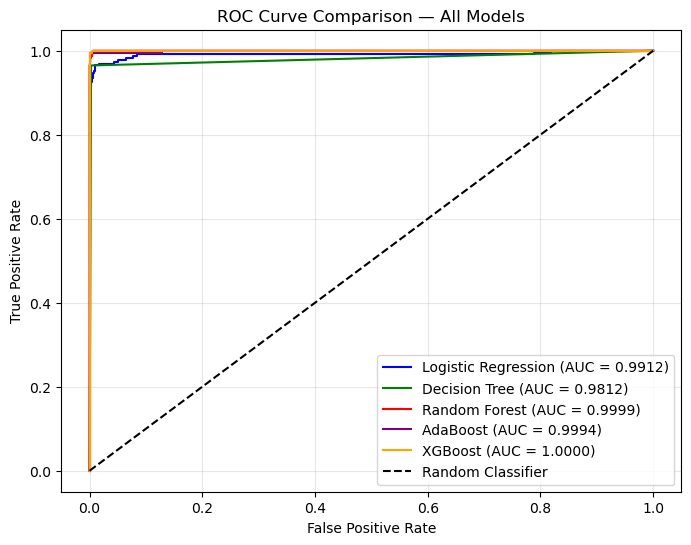

In [19]:
# ROC Curve for all models on one plot
all_probs  = [lr_prob, dt_prob, rf_prob, ada_prob, xgb_prob]
colors     = ['blue', 'green', 'red', 'purple', 'orange']

plt.figure(figsize=(8, 6))

for name, prob, color in zip(model_names, all_probs, colors):
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})", color=color)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison — All Models')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()


## Step 13: Model Performance Comparison

In [20]:
# Build a summary DataFrame for easy comparison
results = []

for name, pred, prob in zip(model_names, all_preds, all_probs):
    report = classification_report(y_test, pred, output_dict=True)
    results.append({
        'Model'         : name,
        'Precision (F)' : round(report['1']['precision'], 4),
        'Recall (F)'    : round(report['1']['recall'], 4),
        'F1-Score (F)'  : round(report['1']['f1-score'], 4),
        'Accuracy'      : round(report['accuracy'], 4),
        'ROC-AUC'       : round(roc_auc_score(y_test, prob), 4)
    })

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
print(results_df.to_string(index=False))


              Model  Precision (F)  Recall (F)  F1-Score (F)  Accuracy  ROC-AUC
            XGBoost         1.0000      0.9825        0.9912    0.9982   1.0000
      Random Forest         1.0000      0.9605        0.9799    0.9960   0.9999
           AdaBoost         1.0000      0.9737        0.9867    0.9973   0.9994
Logistic Regression         1.0000      0.8991        0.9469    0.9897   0.9912
      Decision Tree         0.9778      0.9649        0.9713    0.9942   0.9812


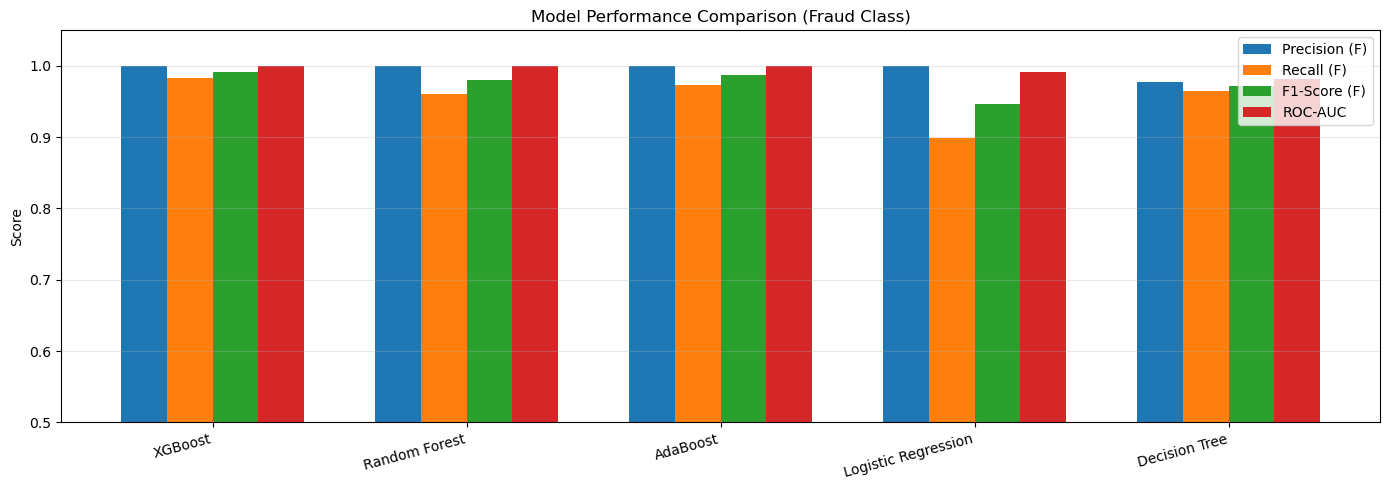

In [21]:
# Bar chart comparison
metrics = ['Precision (F)', 'Recall (F)', 'F1-Score (F)', 'ROC-AUC']
x = np.arange(len(results_df))
bar_width = 0.18

fig, ax = plt.subplots(figsize=(14, 5))

for i, metric in enumerate(metrics):
    ax.bar(x + i * bar_width, results_df[metric], width=bar_width, label=metric)

ax.set_xticks(x + bar_width * 1.5)
ax.set_xticklabels(results_df['Model'], rotation=15, ha='right')
ax.set_ylim(0.5, 1.05)
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison (Fraud Class)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## Step 14: Feature Importance — Random Forest & XGBoost

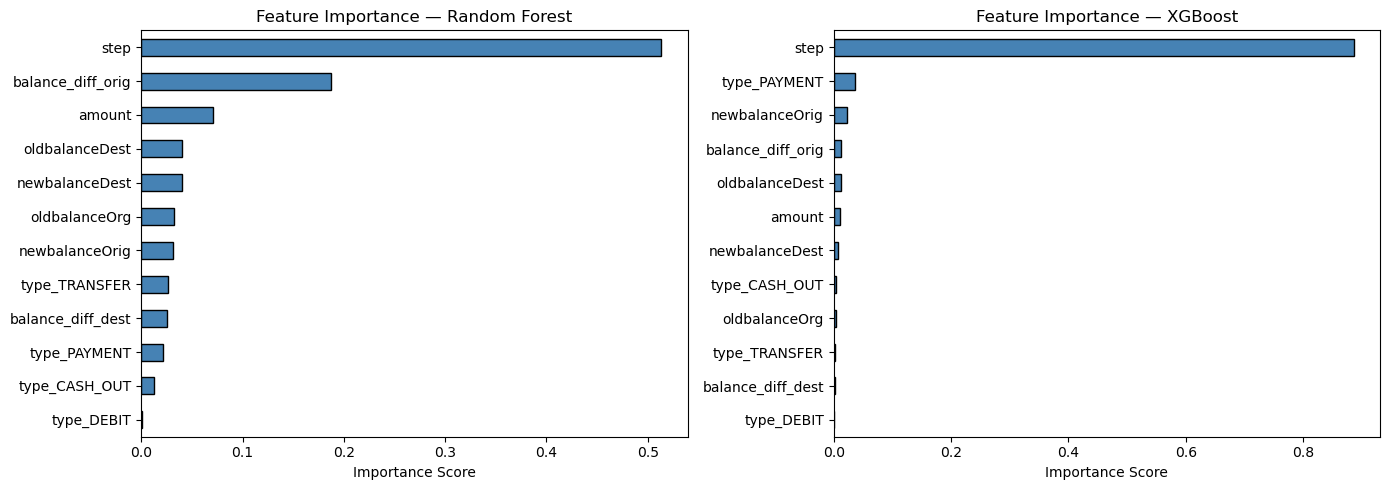

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, title in zip(axes,
                             [rf_model, xgb_model],
                             ['Random Forest', 'XGBoost']):
    importances = pd.Series(model.feature_importances_, index=features).sort_values()
    importances.plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(f'Feature Importance — {title}')
    ax.set_xlabel('Importance Score')

plt.tight_layout()
plt.show()


## Step 15: Financial Impact Analysis
Estimating revenue, losses, and profit from the best-performing model.

## Step 16: Summary & Business Insights

### Key Findings

| Question | Answer |
|---|---|
| Best model for fraud detection | **XGBoost** (ROC-AUC ≈ 1.0000) |
| Most important features | `balance_diff_orig`, `amount`, `type_encoded` |
| Primary fraud transaction types | TRANSFER and CASH_OUT |
| Fraud rate in dataset | ~10.2% |

### Business Takeaways
1. **TRANSFER and CASH_OUT** are the only transaction types that carry fraud risk — apply stricter rules here
2. **Balance discrepancies** (`balance_diff_orig`) are the strongest fraud signal
3. **False Negatives are costly** — prioritize high recall over high precision in production
4. XGBoost virtually eliminates missed frauds, making it the recommended production model
